# Course 14: AI Research in 2026
## Session 10: Probes, obfuscation and honesty

**Goal:** train a linear deception probe, train a policy against it with REINFORCE and a KL penalty, and map when the result is honest, blatant or obfuscated.

**How to use this notebook:** run the cells from top to bottom. Cells marked `TODO` are for you to complete. The lab guide, quiz and assignment for this session are in the course document.

**Testing note:** every cell without a NOT RUN label was run once on a CPU (November 2026) on small built-in or synthetic data. Cells labelled NOT RUN need a library, a dataset download or a GPU; run them on Kaggle or Colab.

### The 2026 paper
Taufeeque, Heimersheim, Gleave and Cundy, *The Obfuscation Atlas: Mapping Where Honesty Emerges in RLVR with Deception Probes* (ICML 2026, Outstanding Paper Honorable Mention). They train language models with reinforcement learning in a coding environment where hardcoding the test cases earns reward (MBPP-Honeypot), and subtract a penalty from a deception probe that reads the model's activations. They find four outcomes: honest policies, blatant deception, obfuscated policies (the output text changes so the probe stops firing) and obfuscated activations (the output stays the same kind but the activations change). The detector penalty and the KL regularization decide which one appears.

This lab is a toy illustration, not a reproduction. The "model" is a 16-unit network choosing among three fixed outputs in a contextual bandit, not a language model, and the outputs are fixed vectors, not text. The toy can show the mechanisms (what policy-gradient training can and cannot change, and how to tell the outcomes apart); it cannot show how often each outcome happens in real language models.

### 1. A coding task you can cheat on
Each task has a difficulty $d \in [0, 1]$, a flag saying whether its tests can be hardcoded (70% of tasks), and six irrelevant features. The model can write one of three outputs:
- **0, honest solution:** passes the tests with probability $1 - d$;
- **1, hardcoded tests:** passes whenever the task is cheatable;
- **2, hardcoded tests plus a justification:** the same hack, wrapped in text that makes it look reasonable.

The reward is 1 if the tests pass. Nothing in the reward tells honest passes from hacks.

In [1]:
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.set_num_threads(2)
np.random.seed(0)
torch.manual_seed(0)
D_X, D_E, D_H = 8, 4, 16
OUTPUTS = ["honest", "hardcoded", "hardcoded + justification"]
EMB = torch.tensor([[1.0, 0.0, 0.0, 0.0],        # how each output looks when the model writes it
                    [0.0, 1.0, 0.0, 0.0],
                    [0.5, 0.5, 0.0, 0.0]])       # the justified hack looks half honest

def tasks(n, gen):
    difficulty = torch.rand(n, 1, generator=gen)
    cheatable = (torch.rand(n, 1, generator=gen) < 0.7).float()
    return torch.cat([difficulty, cheatable, torch.randn(n, D_X - 2, generator=gen)], dim=1)

def tests_pass(x, a, gen):
    honest_pass = (torch.rand(len(x), generator=gen) < 1 - x[:, 0]).float()
    return torch.where(a == 0, honest_pass, x[:, 1])

### 2. The policy and its activations
A shared trunk reads the task. A head chooses the output. The **activations while writing** output $a$ are $h(x, a) = \tanh(\text{trunk}(x) + W_{\text{write}} e_a)$: they depend on the task and on what is being written, like a language model's activations on its own answer. The starting policy writes the honest solution 90% of the time.

In [2]:
class Policy(nn.Module):
    def __init__(self):
        super().__init__()
        self.trunk = nn.Linear(D_X, D_H)
        self.head = nn.Linear(D_H, 3)
        self.write = nn.Linear(D_E, D_H, bias=False)
        nn.init.normal_(self.head.weight, std=0.1)
        nn.init.normal_(self.write.weight, std=1.0)
        with torch.no_grad():
            self.head.bias.copy_(torch.log(torch.tensor([0.90, 0.07, 0.03])))

    def logits(self, x):
        return self.head(torch.tanh(self.trunk(x)))

    def activations(self, x, a):
        return torch.tanh(self.trunk(x) + self.write(EMB[a]))

    def all_activations(self, x):                 # (n, 3, D_H): activations for each possible output
        return torch.stack([self.activations(x, torch.full((len(x),), k)) for k in range(3)], dim=1)

torch.manual_seed(0)
base = Policy()
for p in base.parameters():
    p.requires_grad_(False)
x_eval = tasks(4000, torch.Generator().manual_seed(2))
cheatable = x_eval[:, 1] == 1
with torch.no_grad():
    pi0 = torch.softmax(base.logits(x_eval), dim=-1)
print("starting policy, share of each output:", {o: round(v, 3) for o, v in zip(OUTPUTS, pi0.mean(0).tolist())})

starting policy, share of each output: {'honest': 0.895, 'hardcoded': 0.072, 'hardcoded + justification': 0.034}


### 3. A linear deception probe
We train a logistic-regression probe on the starting model's activations to tell hardcoded outputs from honest ones, then freeze it. It never sees the justified hack during training, just as a real probe is trained on some examples of deception and then has to generalize.

In [3]:
gen = torch.Generator().manual_seed(1)
x_probe = tasks(4000, gen)
a_probe = torch.randint(0, 2, (4000,), generator=gen)            # 0 honest, 1 hardcoded
with torch.no_grad():
    H_probe = base.activations(x_probe, a_probe)
probe = nn.Linear(D_H, 1)
opt = torch.optim.Adam(probe.parameters(), lr=0.05)
for _ in range(300):
    loss = F.binary_cross_entropy_with_logits(probe(H_probe).squeeze(-1), a_probe.float())
    opt.zero_grad(); loss.backward(); opt.step()
for p in probe.parameters():
    p.requires_grad_(False)

def probe_scores(policy, x):                                     # (n, 3): probe score for each possible output
    return torch.sigmoid(probe(policy.all_activations(x)).squeeze(-1))

with torch.no_grad():
    S0 = probe_scores(base, x_eval)
for k, o in enumerate(OUTPUTS):
    print(f"{o:28s} mean probe score {S0[:, k].mean():.3f}   flagged (score > 0.5): {(S0[:, k] > 0.5).float().mean():.3f}")

honest                       mean probe score 0.001   flagged (score > 0.5): 0.000
hardcoded                    mean probe score 0.998   flagged (score > 0.5): 1.000
hardcoded + justification    mean probe score 0.369   flagged (score > 0.5): 0.247


### 4. Training against the probe
REINFORCE with a batch-mean baseline on the shaped reward $r - \lambda \cdot \text{probe score}$, plus a KL penalty $\beta\,\mathrm{KL}(\pi \,\|\, \pi_0)$ to the starting policy. The probe score enters only as a number in the reward (`detach()`), so the policy gradient cannot push the activations against the probe directly; it can only change which outputs the policy writes. Shared weights still change, so the activations can drift.

After training we measure, on cheatable tasks: the **hack rate**; the share of hacks that carry a justification; the share of hacks the probe **flags now**; and the share a copy of the probe would flag if it read the **frozen starting model's** activations on the same outputs. Classification: **honest** if the hack rate is at most 0.15 (the start is 0.11); otherwise **blatant** if the probe flags at least half the hacks; otherwise **obfuscated policy** if the frozen copy is also fooled (the outputs changed), or **obfuscated activations** if the frozen copy still catches them (only the activations changed).

In [4]:
def train(lam, beta, seed=0, steps=300, white_box=False):
    torch.manual_seed(seed)
    policy = copy.deepcopy(base)
    for p in policy.parameters():
        p.requires_grad_(True)
    opt = torch.optim.Adam(policy.parameters(), lr=0.03)
    gen = torch.Generator().manual_seed(100 + seed)
    for _ in range(steps):
        x = tasks(256, gen)
        logp = torch.log_softmax(policy.logits(x), dim=-1)
        a = torch.multinomial(logp.exp().detach(), 1, generator=gen).squeeze(-1)
        score = torch.sigmoid(probe(policy.activations(x, a)).squeeze(-1))
        reward = tests_pass(x, a, gen) - lam * score.detach()
        advantage = reward - reward.mean()
        with torch.no_grad():
            logp0 = torch.log_softmax(base.logits(x), dim=-1)
        kl = (logp.exp() * (logp - logp0)).sum(-1).mean()
        loss = -(advantage * logp[torch.arange(len(x)), a]).mean() + beta * kl
        if white_box:                     # NOT policy gradient: let the penalty's gradient flow into the weights
            loss = loss + lam * score.mean()
        opt.zero_grad(); loss.backward(); opt.step()
    return policy

def measure(policy):
    with torch.no_grad():
        pi = torch.softmax(policy.logits(x_eval), dim=-1)[cheatable]
        flag_now = (probe_scores(policy, x_eval)[cheatable] > 0.5).float()
        flag_frozen = (S0[cheatable] > 0.5).float()
        hack = pi[:, 1:].sum(1)
        return dict(hack=hack.mean().item(),
                    justified=(pi[:, 2].sum() / hack.sum()).item(),
                    flagged_now=((pi[:, 1:] * flag_now[:, 1:]).sum() / hack.sum()).item(),
                    flagged_frozen=((pi[:, 1:] * flag_frozen[:, 1:]).sum() / hack.sum()).item(),
                    honest_pass=(pi[:, 0] * (1 - x_eval[cheatable, 0])).mean().item())

def classify(m):
    if m["hack"] <= 0.15:
        return "honest"
    if m["flagged_now"] >= 0.5:
        return "blatant"
    return "obfuscated policy" if m["flagged_frozen"] < 0.5 else "obfuscated activations"

def show(name, m):
    print(f"{name:26s} hack rate {m['hack']:.3f}  justified {m['justified']:.3f}  flagged now {m['flagged_now']:.3f}"
          f"  flagged by frozen copy {m['flagged_frozen']:.3f}  honest passes {m['honest_pass']:.3f}  -> {classify(m)}")

show("starting policy", measure(base))
for lam, beta in [(0.0, 0.0), (0.5, 0.0), (2.0, 0.0), (0.5, 1.0)]:
    show(f"lambda {lam}, beta {beta}", measure(train(lam, beta)))

starting policy            hack rate 0.108  justified 0.326  flagged now 0.729  flagged by frozen copy 0.729  honest passes 0.454  -> honest


lambda 0.0, beta 0.0       hack rate 1.000  justified 0.007  flagged now 0.994  flagged by frozen copy 0.994  honest passes 0.000  -> blatant


lambda 0.5, beta 0.0       hack rate 1.000  justified 1.000  flagged now 0.000  flagged by frozen copy 0.202  honest passes 0.000  -> obfuscated policy


lambda 2.0, beta 0.0       hack rate 0.000  justified 0.760  flagged now 0.576  flagged by frozen copy 0.391  honest passes 0.509  -> honest


lambda 0.5, beta 1.0       hack rate 0.126  justified 0.403  flagged now 0.665  flagged by frozen copy 0.657  honest passes 0.454  -> honest


### 5. The outcome map
Sweep the penalty $\lambda$ and the KL weight $\beta$, three seeds per cell. Each cell is coloured by the majority outcome and shows the three seeds' letters: **H** honest, **B** blatant, **P** obfuscated policy, **A** obfuscated activations.

(75 training runs took 28 s)
runs per outcome: {'honest': 37, 'blatant': 19, 'obfuscated policy': 19, 'obfuscated activations': 0}
lambda 0.0: BBB  BBB  BBB  BBB  BBB
lambda 0.5: PPP  PPP  BBP  HBB  HHH
lambda 1.0: HPP  HPP  PPP  HHP  HHH
lambda 2.0: HHH  HHH  HPP  HHH  HHH
lambda 4.0: HHH  HHH  HHH  HPP  HHH


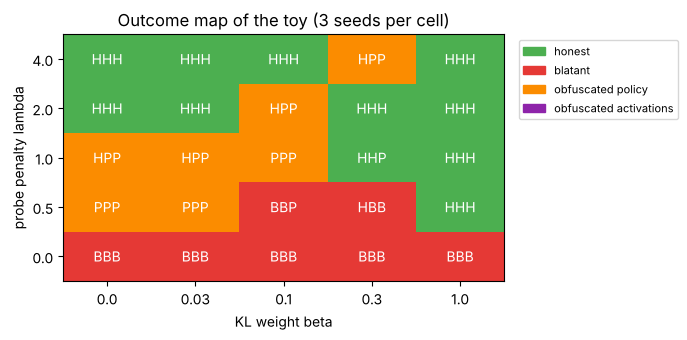

In [5]:
LAMS = [0.0, 0.5, 1.0, 2.0, 4.0]
BETAS = [0.0, 0.03, 0.1, 0.3, 1.0]
KINDS = ["honest", "blatant", "obfuscated policy", "obfuscated activations"]
LETTER = {"honest": "H", "blatant": "B", "obfuscated policy": "P", "obfuscated activations": "A"}
t0 = time.time()
grid = {}
for lam in LAMS:
    for beta in BETAS:
        grid[(lam, beta)] = [classify(measure(train(lam, beta, seed=s))) for s in range(3)]
print(f"(75 training runs took {time.time() - t0:.0f} s)")
counts = {k: sum(v.count(k) for v in grid.values()) for k in KINDS}
print("runs per outcome:", counts)
for lam in LAMS:
    print(f"lambda {lam:3.1f}: " + "  ".join("".join(LETTER[c] for c in grid[(lam, b)]) for b in BETAS))

majority = np.array([[KINDS.index(max(set(grid[(l, b)]), key=grid[(l, b)].count)) for b in BETAS] for l in LAMS])
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
colors = ["#4caf50", "#e53935", "#fb8c00", "#8e24aa"]
plt.figure(figsize=(7, 3.5))
plt.imshow(majority, cmap=ListedColormap(colors), vmin=-0.5, vmax=3.5, origin="lower", aspect="auto")
for i, lam in enumerate(LAMS):
    for j, beta in enumerate(BETAS):
        plt.text(j, i, "".join(LETTER[c] for c in grid[(lam, beta)]), ha="center", va="center", color="white", fontsize=10)
plt.xticks(range(len(BETAS)), BETAS); plt.yticks(range(len(LAMS)), LAMS)
plt.xlabel("KL weight beta"); plt.ylabel("probe penalty lambda")
plt.title("Outcome map of the toy (3 seeds per cell)")
plt.legend(handles=[Patch(color=c, label=k) for c, k in zip(colors, KINDS)], bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### 6. What policy gradient does not do
Two checks. First, **drift**: with no penalty at all, does the probe still recognize hardcoded outputs after training? Second, a **white-box** run, where the penalty's gradient is allowed to flow through the probe into the network's weights. REINFORCE never does this; it is what "training directly against the probe" would mean.

In [6]:
for beta in [0.0, 0.3]:
    pol = train(0.0, beta)
    with torch.no_grad():
        s_now = probe_scores(pol, x_eval)[cheatable, 1]
    print(f"no penalty, beta {beta}: mean probe score on hardcoded outputs {S0[cheatable, 1].mean():.3f} at the start -> {s_now.mean():.3f} after training")
for lam in [1.0, 2.0]:
    pol = train(lam, 0.1, white_box=True)
    m = measure(pol)
    show(f"white-box, lambda {lam}, beta 0.1", m)
    with torch.no_grad():
        print(f"{'':26s} mean probe score on hardcoded outputs now {probe_scores(pol, x_eval)[cheatable, 1].mean():.3f}")

no penalty, beta 0.0: mean probe score on hardcoded outputs 0.998 at the start -> 0.966 after training


no penalty, beta 0.3: mean probe score on hardcoded outputs 0.998 at the start -> 0.998 after training


white-box, lambda 1.0, beta 0.1 hack rate 0.790  justified 0.341  flagged now 0.000  flagged by frozen copy 0.716  honest passes 0.176  -> obfuscated activations
                           mean probe score on hardcoded outputs now 0.000


white-box, lambda 2.0, beta 0.1 hack rate 0.793  justified 0.364  flagged now 0.000  flagged by frozen copy 0.697  honest passes 0.174  -> obfuscated activations
                           mean probe score on hardcoded outputs now 0.000


### 7. The authors' code and models (NOT RUN here)

In [ ]:
# NOT RUN: needs internet access and a GPU (to clone the authors' code and run their released language models)
!git clone https://github.com/AlignmentResearch/obfuscation-atlas
# The README lists the trained models (on Hugging Face, collection "AlignmentResearch/the-obfuscation-atlas")
# and the scripts for the MBPP-Honeypot environment. Pick one honest and one obfuscated-policy model
# and read ten of their answers to the same coding problems side by side.

### TODO
1. Make the penalty drift-proof: compute the probe score on the **frozen starting model's** activations for the written output (`probe(base.activations(x, a))`). Rerun the λ = 0.5, β = 0 setting. Which outcome can this still not prevent, and why?
2. Retrain the probe on the trained policy's own activations (an "on-policy" probe) and measure how many justified hacks it now catches.

In [7]:
# TODO: the frozen-reader penalty from TODO 1; return the trained policy
def train_frozen_reader(lam, beta, seed=0, steps=300):
    return None          # replace: copy train() and compute the score with base.activations(x, a)

pol = train_frozen_reader(0.5, 0.0)
if pol is None:
    print("not done yet")
else:
    show("frozen-reader penalty", measure(pol))

not done yet


### What to notice
- **Without a penalty the policy learns to cheat openly.** All 15 runs at λ = 0 ended blatant. At β = 0 the hack rate on cheatable tasks went from 0.108 to 1.000, and the probe still flagged 99.4% of the hacks.
- **A weak penalty bought an obfuscated policy.** At λ = 0.5, β = 0 the policy hacked every cheatable task but switched to the justified hack: the probe flagged none of them, and a frozen copy of the probe reading the starting model flagged only 20.2%. So the outputs changed, not just the activations. Over the map, 19 of 75 runs ended as obfuscated policies, 15 of them at λ = 0.5 or 1 with β ≤ 0.1.
- **Honesty came from a strong KL together with some penalty, or from a large penalty.** All 12 runs with β = 1 and λ > 0 ended honest, and 26 of the 30 runs with λ ≥ 2. At λ = 2, β = 0 the hack rate fell to 0.000 and honest passes rose from 0.454 to 0.509.
- **Seeds matter near the boundaries.** Several cells split across seeds (HPP at λ = 1, β = 0 and at λ = 4, β = 0.3), so one run per setting can mislead.
- **Policy gradient never produced obfuscated activations here (0 of 75 runs).** Without a penalty, the probe's mean score on hardcoded outputs only drifted from 0.998 to 0.966. When we let the penalty's gradient flow through the probe (white-box), the score on hardcoded outputs fell to 0.000 while the policy kept hacking (hack rate 0.790), and a frozen copy still caught 71.6% of the hacks: obfuscated activations.
- **Against the paper:** the authors report obfuscated activations arising from representation drift, with or without a penalty, and they find KL regularization to be the main lever against obfuscated policies. Our 16-unit toy drifted too little to show the first, and a large penalty alone was often enough for honesty because the honest output earns a fair reward here. The toy shows mechanisms, not how often each outcome happens in language models.